In [1]:
!pip install -q kagglehub onnx onnxscript onnxruntime

import os, json, random, shutil
import numpy as np
import torch, torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub
from google.colab import drive

drive.mount('/content/drive')   # click Allow when asked

def set_seed(s=42):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")

def find_root(base):
    for dp, dn, fn in os.walk(base):
        if len(dn) >= 5 and all(
            any(f.lower().endswith(('.jpg', '.jpeg', '.png'))
                for f in os.listdir(os.path.join(dp, d)))
            for d in dn):
            return dp

DATA_DIR = find_root(path)
print("Dataset folder:", DATA_DIR)
print(os.listdir(DATA_DIR))

Mounted at /content/drive
Device: cuda
Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification
['metal', 'glass', 'paper', 'trash', 'cardboard', 'plastic']


In [2]:
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), norm])

full_train = datasets.ImageFolder(DATA_DIR, train_tf)
full_eval = datasets.ImageFolder(DATA_DIR, eval_tf)
classes = full_train.classes
n = len(full_train)
print("Classes:", classes, "| Images:", n)

g = torch.Generator().manual_seed(42)
idx = torch.randperm(n, generator=g).tolist()
n_tr, n_va = int(0.70 * n), int(0.15 * n)
train_ds = Subset(full_train, idx[:n_tr])
val_ds = Subset(full_eval, idx[n_tr:n_tr + n_va])
test_ds = Subset(full_eval, idx[n_tr + n_va:])
print("Train/Val/Test:", len(train_ds), len(val_ds), len(test_ds))

def make_train_dl():
    gen = torch.Generator().manual_seed(42)
    return DataLoader(train_ds, batch_size=32, shuffle=True,
                      num_workers=2, generator=gen)

val_dl = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash'] | Images: 2527
Train/Val/Test: 1768 379 380


In [3]:
def build_model(name):
    if name == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.last_channel, len(classes))
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, len(classes))
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(classes))
    return m.to(device)

def run_epoch(model, dl, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, correct, total = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return loss_sum / total, correct / total

EPOCHS, PATIENCE = 10, 3
results, histories = {}, {}

for name in ["mobilenet_v2", "resnet18", "efficientnet_b0"]:
    print(f"\n=== Training {name} ===")
    set_seed(42)
    train_dl = make_train_dl()
    model = build_model(name)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, bad = 0, 0
    for epoch in range(EPOCHS):
        tl, ta = run_epoch(model, train_dl, criterion, optimizer)
        vl, va = run_epoch(model, val_dl, criterion)
        scheduler.step()
        for k, v in zip(hist, [tl, vl, ta, va]):
            hist[k].append(v)
        print(f"Epoch {epoch+1}/{EPOCHS} | train acc {ta:.3f} | val acc {va:.3f}")
        if va > best_acc:
            best_acc, bad = va, 0
            torch.save(model.state_dict(), f"/content/{name}.pth")
        else:
            bad += 1
            if bad >= PATIENCE:
                print("Early stopping"); break
    results[name] = best_acc
    histories[name] = hist

print("\nValidation accuracy by model:")
for k, v in results.items():
    print(f"  {k}: {v:.4f}")


=== Training mobilenet_v2 ===
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]


Epoch 1/10 | train acc 0.663 | val acc 0.831
Epoch 2/10 | train acc 0.878 | val acc 0.873
Epoch 3/10 | train acc 0.936 | val acc 0.897
Epoch 4/10 | train acc 0.967 | val acc 0.910
Epoch 5/10 | train acc 0.976 | val acc 0.916
Epoch 6/10 | train acc 0.984 | val acc 0.921
Epoch 7/10 | train acc 0.989 | val acc 0.937
Epoch 8/10 | train acc 0.992 | val acc 0.945
Epoch 9/10 | train acc 0.997 | val acc 0.937
Epoch 10/10 | train acc 0.994 | val acc 0.939

=== Training resnet18 ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 200MB/s]


Epoch 1/10 | train acc 0.737 | val acc 0.794
Epoch 2/10 | train acc 0.881 | val acc 0.826
Epoch 3/10 | train acc 0.932 | val acc 0.828
Epoch 4/10 | train acc 0.961 | val acc 0.900
Epoch 5/10 | train acc 0.985 | val acc 0.887
Epoch 6/10 | train acc 0.987 | val acc 0.897
Epoch 7/10 | train acc 0.995 | val acc 0.918
Epoch 8/10 | train acc 0.998 | val acc 0.918
Epoch 9/10 | train acc 0.997 | val acc 0.923
Epoch 10/10 | train acc 0.996 | val acc 0.916

=== Training efficientnet_b0 ===
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 159MB/s]


Epoch 1/10 | train acc 0.692 | val acc 0.831
Epoch 2/10 | train acc 0.895 | val acc 0.892
Epoch 3/10 | train acc 0.947 | val acc 0.916
Epoch 4/10 | train acc 0.969 | val acc 0.902
Epoch 5/10 | train acc 0.977 | val acc 0.939
Epoch 6/10 | train acc 0.982 | val acc 0.931
Epoch 7/10 | train acc 0.993 | val acc 0.937
Epoch 8/10 | train acc 0.993 | val acc 0.937
Early stopping

Validation accuracy by model:
  mobilenet_v2: 0.9446
  resnet18: 0.9235
  efficientnet_b0: 0.9393


Best model: mobilenet_v2
TEST ACCURACY: 0.9316
              precision    recall  f1-score   support

   cardboard       0.98      0.97      0.97        59
       glass       0.90      0.97      0.94        78
       metal       0.88      0.97      0.92        61
       paper       0.94      0.98      0.96        92
     plastic       0.96      0.83      0.89        66
       trash       0.94      0.71      0.81        24

    accuracy                           0.93       380
   macro avg       0.94      0.90      0.92       380
weighted avg       0.93      0.93      0.93       380



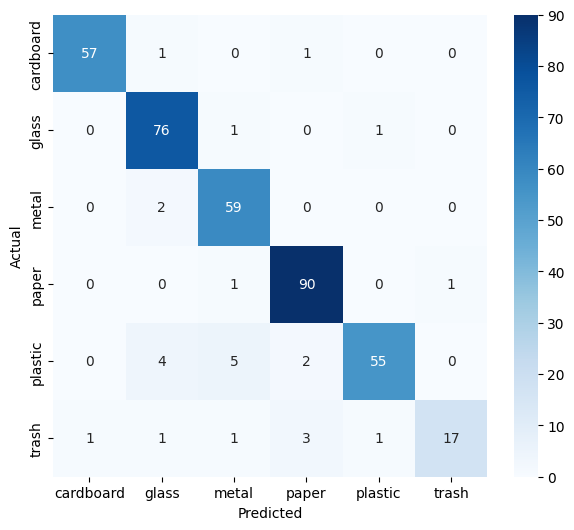

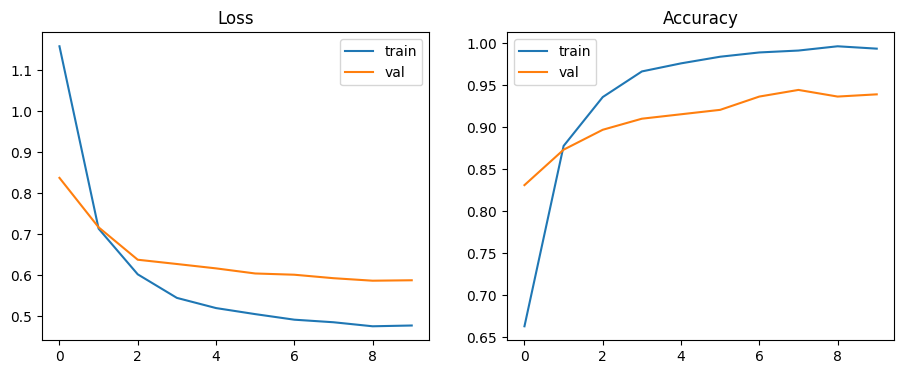

In [4]:
best_name = max(results, key=results.get)
print("Best model:", best_name)
model = build_model(best_name)
model.load_state_dict(torch.load(f"/content/{best_name}.pth", map_location=device))
model.eval()
shutil.copy(f"/content/{best_name}.pth", "/content/waste_model.pth")

preds, labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        labels += y.tolist()

test_acc = sum(p == l for p, l in zip(preds, labels)) / len(labels)
print(f"TEST ACCURACY: {test_acc:.4f}")
report = classification_report(labels, preds, target_names=classes)
print(report)
open("/content/classification_report.txt", "w").write(report)

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt="d",
            xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig("/content/confusion_matrix.png", bbox_inches="tight"); plt.show()

h = histories[best_name]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.savefig("/content/training_curves.png", bbox_inches="tight"); plt.show()

json.dump({"best_model": best_name, "test_accuracy": test_acc,
           "validation_accuracy_by_model": results, "classes": classes,
           "split": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)}},
          open("/content/results.json", "w"), indent=2)

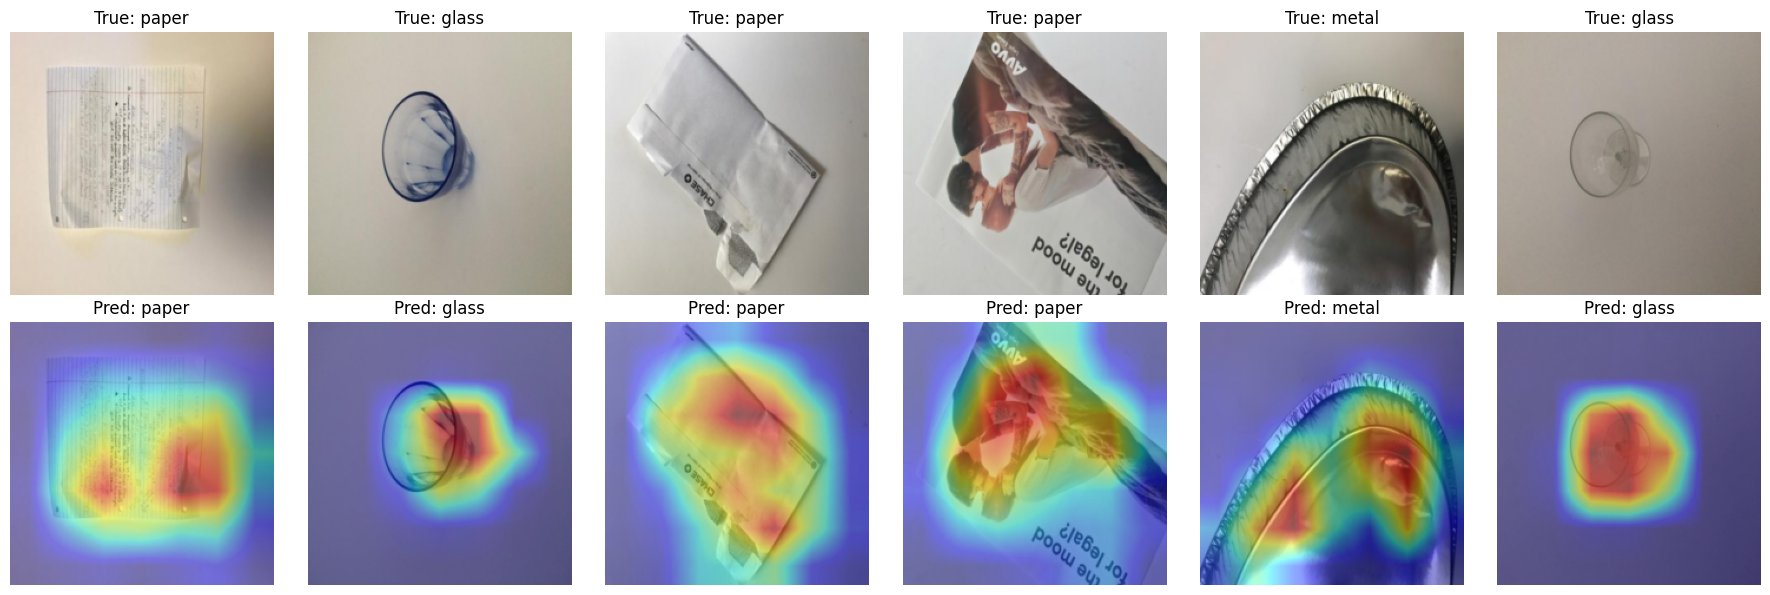

In [5]:
def target_layer(name, m):
    return m.layer4[-1] if name == "resnet18" else m.features[-1]

def gradcam(m, x, layer):
    acts, grads = [], []
    def fwd(mod, i, o):
        acts.append(o)
        o.register_hook(lambda gr: grads.append(gr))
    hd = layer.register_forward_hook(fwd)
    with torch.enable_grad():
        out = m(x)
        cls = out.argmax(1).item()
        m.zero_grad(); out[0, cls].backward()
    hd.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), cls

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for i in range(6):
    x, y = test_ds[i * 7]
    cam, pred = gradcam(model, x.unsqueeze(0).to(device), target_layer(best_name, model))
    img = (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[0, i].imshow(img); axes[0, i].set_title(f"True: {classes[y]}"); axes[0, i].axis("off")
    axes[1, i].imshow(img); axes[1, i].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, i].set_title(f"Pred: {classes[pred]}"); axes[1, i].axis("off")
plt.tight_layout()
plt.savefig("/content/gradcam.png", bbox_inches="tight"); plt.show()

In [6]:
model.cpu().eval()
dummy = torch.randn(1, 3, 224, 224)
try:
    torch.onnx.export(model, dummy, "/content/waste_model.onnx",
                      input_names=["input"], output_names=["output"],
                      opset_version=12, dynamo=False)
except TypeError:
    torch.onnx.export(model, dummy, "/content/waste_model.onnx",
                      input_names=["input"], output_names=["output"],
                      opset_version=12)
json.dump(classes, open("/content/labels.json", "w"))

os.makedirs("/content/samples", exist_ok=True)
for j in range(12):
    p, lab = full_eval.samples[idx[n_tr + n_va + j]]
    shutil.copy(p, f"/content/samples/{classes[lab]}_{j}.jpg")
shutil.make_archive("/content/samples", "zip", "/content/samples")
print("Done")

/tmp/ipykernel_3730/2136021963.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, "/content/waste_model.onnx",


Done


In [7]:
import onnxruntime as ort

m = build_model(best_name)
m.load_state_dict(torch.load("/content/waste_model.pth", map_location=device))
m.eval()
correct, total = 0, 0
with torch.no_grad():
    for x, y in test_dl:
        correct += (m(x.to(device)).argmax(1).cpu() == y).sum().item()
        total += len(y)
print(f"Saved weights on test set: {correct}/{total} = {correct/total:.4f}")
print("results.json says:", json.load(open("/content/results.json"))["test_accuracy"])

sess = ort.InferenceSession("/content/waste_model.onnx")
agree = 0
for i in range(100):
    x, _ = test_ds[i]
    o = sess.run(None, {"input": x.unsqueeze(0).numpy()})[0]
    with torch.no_grad():
        p = m(x.unsqueeze(0).to(device)).argmax(1).item()
    agree += int(o.argmax() == p)
print(f"ONNX vs PyTorch agreement: {agree}/100")

names = ["waste_model.pth", "waste_model.onnx", "labels.json", "results.json",
         "classification_report.txt", "confusion_matrix.png",
         "training_curves.png", "gradcam.png", "samples.zip"]
os.makedirs("/content/drive/MyDrive/waste_project", exist_ok=True)
for f in names:
    shutil.copy("/content/" + f, "/content/drive/MyDrive/waste_project/" + f)
print("Backed up to Google Drive")

from google.colab import files
for f in names:
    files.download("/content/" + f)

Saved weights on test set: 354/380 = 0.9316
results.json says: 0.9315789473684211
ONNX vs PyTorch agreement: 100/100
Backed up to Google Drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>